# 05 · SinDDM on Colab: port check, training speed, resume (Phase 2)

**T4 GPU runtime.** About 25–35 min.

SinDDM pins Python 3.8 / torch 1.13, which Colab cannot install, so we run our port:
`patches/sinddm_port/` replaces 3 files (see `CHANGES.diff`):
- a device option;
- resumable, time-budgeted training;
- safe weights-only checkpoint loading;
- a scikit-image API fix.

This notebook:
1. samples the 3 official pretrained models;
2. measures **seconds per 1 000 training steps** at the native size and at a 128-px short side;
3. tests stop-and-resume.

In [1]:
# ==== SETTINGS (edit once) ====================================================================
CODE_SOURCE   = "github"                                      # "github" or "drive"
GITHUB_REPO   = "https://github.com/rishabh-vr/CS787-Single-Image-Diffusion-Editor.git"
GITHUB_BRANCH = "main"
REPO_SUBDIR   = ""                                            # project files are at the repo root
DRIVE_CODE    = "/content/drive/MyDrive/CS787/code/Project"   # used when CODE_SOURCE == "drive"
DRIVE_ROOT    = "/content/drive/MyDrive/CS787"                # outputs, checkpoints, tables, env logs
SID_COMMIT    = "85381e3c6f29fc07144da854d86be07150404716"     # official code, audited commit
SINDDM_COMMIT = "e7107d9fd198928f26e278f99ec428e261726a45"  # SinDDM, audited commit
# If the GitHub repo is private: add a Colab secret named GH_TOKEN (key icon in the left bar)
# holding a fine-grained, read-only token for that repo.

NOTEBOOK = "05_sinddm_port"

In [2]:
import torch, subprocess
assert torch.cuda.is_available(), "No GPU: Runtime > Change runtime type > T4 GPU (then rerun)."
print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv"],
                     capture_output=True, text=True).stdout)
print("torch", torch.__version__, "| CUDA", torch.version.cuda,
      "| bf16 native:", torch.cuda.get_device_capability(0) >= (8, 0))

name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07

torch 2.14.1+cu130 | CUDA 13.0 | bf16 native: False


In [3]:
import os, shutil, subprocess, sys
from google.colab import drive
drive.mount("/content/drive")
for sub in ("outputs", "checkpoints", "tables", "env_logs", "data"):
    os.makedirs(f"{DRIVE_ROOT}/{sub}", exist_ok=True)

PROJECT = "/content/project"
if os.path.exists(PROJECT):
    shutil.rmtree(PROJECT)
if CODE_SOURCE == "github":
    url = GITHUB_REPO
    try:
        from google.colab import userdata
        token = userdata.get("GH_TOKEN")
        url = GITHUB_REPO.replace("https://", f"https://x-access-token:{token}@")
    except Exception:
        pass  # public repo: no token needed
    subprocess.run(["git", "clone", "-q", "--depth", "1", "-b", GITHUB_BRANCH, url, "/content/repo"], check=True)
    shutil.copytree(os.path.join("/content/repo", REPO_SUBDIR), PROJECT,
                    ignore=shutil.ignore_patterns(".venv", "external", "outputs*"))
else:
    shutil.copytree(DRIVE_CODE, PROJECT, ignore=shutil.ignore_patterns(".venv", "external", "outputs*"))
print("project code at", PROJECT, "->", sorted(os.listdir(PROJECT)))

Mounted at /content/drive
project code at /content/project -> ['.git', '.gitignore', '2606.04299v1.pdf', 'PROJECT_PLAN.md', 'README.md', 'configs', 'docs', 'env', 'notebooks', 'patches', 'pyproject.toml', 'scripts', 'src', 'tests']


In [4]:
SINDDM = "/content/SinDDM"
if not os.path.exists(SINDDM):
    subprocess.run(["git", "clone", "-q", "https://github.com/fallenshock/SinDDM", SINDDM], check=True)
subprocess.run(["git", "-C", SINDDM, "checkout", "-q", "--", "."], check=True)
subprocess.run(["git", "-C", SINDDM, "checkout", "-q", SINDDM_COMMIT], check=True)
shutil.copytree(f"{PROJECT}/patches/sinddm_port", SINDDM, dirs_exist_ok=True,
                ignore=shutil.ignore_patterns("CHANGES.diff"))
!pip install -q einops ftfy scikit-image
print(subprocess.run(["git", "-C", SINDDM, "status", "--short"], capture_output=True, text=True).stdout)

 M SinDDM/functions.py
 M SinDDM/trainer.py
 M main.py



## 1 · Sample the 3 official pretrained models (validates the port)

In [5]:
%cd {SINDDM}
for scope in ("forest", "night_sky", "pyramids"):
    cmd = (f"python main.py --scope {scope} --mode sample --dataset_folder ./datasets/{scope}/ "
           f"--image_name {scope}.png --results_folder ./results/ --load_milestone 12 "
           f"--sample_batch_size 4 --seed 0 2>&1 | grep -v -i warn | tail -3")
    !{cmd}
# If loading fails with "Unsupported global", the official checkpoint holds another type:
# add it to the allow-list in patches/sinddm_port/SinDDM/trainer.py (load) and rerun.

/content/SinDDM
sampling loop time step: 100%|██████████| 23/23 [00:02<00:00,  9.89it/s]


forest


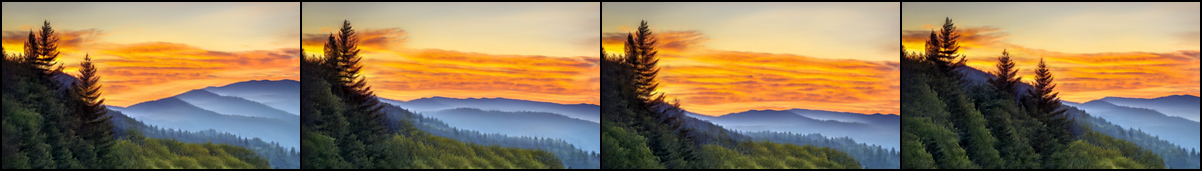

night_sky


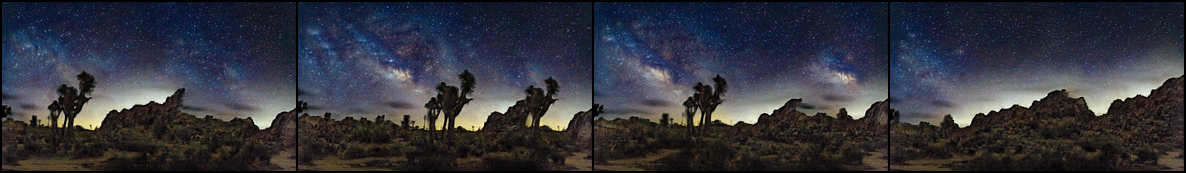

pyramids


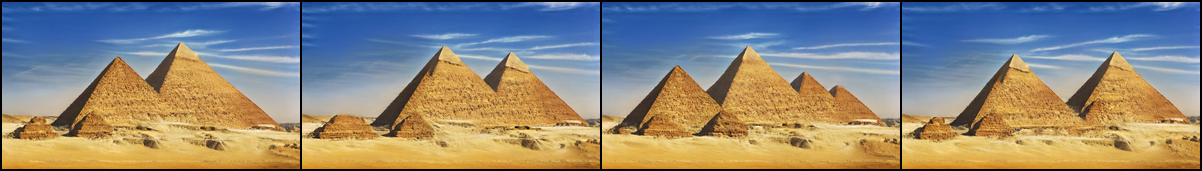

In [6]:
import glob
from IPython.display import Image as IPImage, display
for scope in ("forest", "night_sky", "pyramids"):
    grid = sorted(glob.glob(f"{SINDDM}/results/{scope}/final_samples/*_out_s*"))
    if grid:
        print(scope); display(IPImage(grid[-1], width=600))

## 2 · Training speed (steady-state seconds per 1 000 steps)
Each size is trained twice from scratch, for 100 and for 400 steps. The difference divided by 300 gives the
steady-state cost per step, with start-up (and, on TPU, graph compilation) cancelled out. Notebook 07
uses the identical method on the TPU, so the two numbers are directly comparable.

In [7]:
import time, json, re
from PIL import Image
DEVICE_ARGS = ""
os.chdir(SINDDM)
def make_input(name, short_side=None):
    d = f"/content/sinddm_bench/{name}/"; os.makedirs(d, exist_ok=True)
    im = Image.open(f"{SINDDM}/datasets/balloons/balloons.png").convert("RGB")
    if short_side:
        w, h = im.size; s = short_side / min(w, h)
        im = im.resize((round(w * s), round(h * s)), Image.LANCZOS)
    im.save(d + f"{name}.png"); return d, im.size

def train_seconds(scope, folder, image, steps):
    cmd = (f"python main.py --scope {scope} --mode train --dataset_folder {folder} --image_name {image} "
           f"--results_folder /content/sinddm_bench/results_{steps}/ --train_num_steps {steps} "
           f"--save_and_sample_every 1000000 --checkpoint_every_min 1000 --skip_final_sample --seed 0 {DEVICE_ARGS}")
    t0 = time.time()
    out = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    dt = time.time() - t0
    losses = re.findall(r"step:(\d+) loss:([0-9.eE+-]+)", out.stdout)
    if out.returncode != 0 or "training completed" not in out.stdout:
        print(out.stdout[-2000:], out.stderr[-3000:])
        raise RuntimeError(f"training failed ({scope}, {steps} steps)")
    return dt, losses

results = {"device": "T4 GPU", "device_args": DEVICE_ARGS}
for name, short in (("bench_native", None), ("bench_128", 128)):
    folder, size = make_input(name, short)
    t100, _ = train_seconds(name, folder, f"{name}.png", 100)
    t400, losses = train_seconds(name, folder, f"{name}.png", 400)
    per_1000 = (t400 - t100) / 300 * 1000
    results[name] = {"input_wh": list(size), "wall_100_steps_s": round(t100, 1), "wall_400_steps_s": round(t400, 1),
                     "steady_seconds_per_1000_steps": round(per_1000, 1),
                     "full_120k_schedule_hours": round(per_1000 * 120 / 3600, 1),
                     "loss_trace_400": [(int(a), round(float(b), 4)) for a, b in losses]}
    print(f"{name} {size}: {per_1000:.1f} s / 1000 steps  ->  full 120k schedule ~{per_1000*120/3600:.1f} h")
json.dump(results, open(f"{DRIVE_ROOT}/tables/phase2_sinddm_timing.json", "w"), indent=2)
print("saved", f"{DRIVE_ROOT}/tables/phase2_sinddm_timing.json")

bench_native (248, 186): 1395.2 s / 1000 steps  ->  full 120k schedule ~46.5 h
bench_128 (171, 128): 712.2 s / 1000 steps  ->  full 120k schedule ~23.7 h
saved /content/drive/MyDrive/CS787/tables/phase2_sinddm_timing.json


## 3 · Stop-and-resume test (checkpoints on Drive)

In [8]:
ck = f"{DRIVE_ROOT}/checkpoints/sinddm_resume_test/"
folder, _ = make_input("resume_test", 128)
cmd = (f"python main.py --scope resume_test --mode train --dataset_folder {folder} --image_name resume_test.png "
       f"--results_folder {ck} --train_num_steps 400 --save_and_sample_every 1000000 --resume "
       f"--time_budget_min 0.5 --checkpoint_every_min 0.25 --sample_batch_size 1 --seed 0 "
       f"2>&1 | grep -E 'port|completed' | tail -3")
for attempt in (1, 2):
    print(f"--- run {attempt}")
    !{cmd}
print("expected: run 1 stops on the time budget; run 2 says 'resumed from step N' with N > 0")

--- run 1
[port] periodic checkpoint at step 23
[port] time budget reached at step 42; saved model-last.pt
[port] stopped by time budget; rerun with --resume to continue
--- run 2
[port] periodic checkpoint at step 65
[port] time budget reached at step 84; saved model-last.pt
[port] stopped by time budget; rerun with --resume to continue
expected: run 1 stops on the time budget; run 2 says 'resumed from step N' with N > 0


In [9]:
import datetime
stamp = datetime.datetime.now().strftime("%Y-%m-%d_%H%M")
!pip freeze > {DRIVE_ROOT}/env_logs/{stamp}_{NOTEBOOK}_freeze.txt
print("saved", f"{DRIVE_ROOT}/env_logs/{stamp}_{NOTEBOOK}_freeze.txt")

saved /content/drive/MyDrive/CS787/env_logs/2026-11-13_1413_05_sinddm_port_freeze.txt
